In [1]:
# 模擬データ背景の仮モデル 
#
# Workload ─┐
#           ├→ Demand ─┐
# Physical ─┘          │
#                      ├→ Fatigue ──┐
# Environment ─────────┘            │
#                                   ├→ Anxiety ─→ Depression ─→ Symptoms
# Relations ────────────────────────┘
#
# Coworker ─┐
#           ├→ SubSupport ─┐
#           │              │
# Family ───┘              │
#                          ├→ Vigor ────────┐
# Control ─────────────────┤                │
# SkillUse ────────────────┤                │
# Meaning ─────────────────┘                │
#                                           │
# Fit ──────────────────────────────────────┤
# Relations ────────────────────────────────┤
#                                           ↓
#                                     Satisfaction
#
#「職場環境要因 → 仕事要求 → ストレス反応 → 健康障害」「資源 → 活気 → 満足度」というジョブ・デマンド-リソース（JD-R）モデル寄りの構造


In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import shapiro

from lingam import DirectLiNGAM
from lingam.utils import make_dot

In [3]:
np.random.seed(42)

# 作成する乱数の個数
n = 1000

# 作成した乱数を5件法に変換する関数
def to_score(x):
    """
    変換：　連続値 → 1～5点
    """
    return np.select( # 条件に応じて点数を割り当てる
        [
            x < -1.5,                 # 1点
            (-1.5 <= x) & (x < -0.5), # 2点
            (-0.5 <= x) & (x < 0.5),  # 3点
            (0.5 <= x) & (x < 1.5),   # 4点
            x >= 1.5                  # 5点
        ],
        [1, 2, 3, 4, 5]
    )

# ======================
# 外生変数
# ======================

Workload = np.random.laplace(0, 1, n)
Physical = np.random.laplace(0, 1, n)
Environment = np.random.laplace(0, 1, n)

Coworker = np.random.laplace(-0.5, 1, n)
Family = np.random.laplace(1, 1, n)

Control = np.random.laplace(0.5, 1, n)
SkillUse = np.random.laplace(0, 1, n)
Meaning = np.random.laplace(0, 1, n)

Relations = np.random.laplace(-0.5, 1, n)

Fit = np.random.laplace(-0.5, 1, n)

# ======================
# 内生変数
# ======================

SubSupport = (
    0.70 * Coworker
    + 0.30 * Family 
    + np.random.laplace(0, 0.5, n) 
)

Demand = (
    0.70 * Workload
    + 0.30 * Physical
    + np.random.laplace(0, 0.5, n)
)

Fatigue = (
    0.45 * Demand
    + 0.30 * Physical
    + 0.20 * Environment
    + np.random.laplace(0, 0.7, n)
)

Anxiety = (
    0.50 * Fatigue
    + 0.20 * Relations
    + np.random.laplace(0, 0.7, n)
)

Depression = (
    0.60 * Anxiety
    + 0.20 * Fatigue
    + 0.20 * SubSupport
    + np.random.laplace(0, 0.7, n)
)

Symptoms = (
    0.50 * Depression
    + 0.30 * Fatigue
    + np.random.laplace(0, 0.7, n)
)

Irritation = (
    0.40 * Demand
    + 0.30 * Fatigue
    + 0.20 * Relations
    + np.random.laplace(0, 0.7, n)
)

Vigor = (
    0.30 * Control
    + 0.25 * SkillUse
    + 0.25 * Meaning
    + 0.20 * SubSupport
    + 0.25 * Fatigue
    + np.random.laplace(0, 0.7, n)
)

Satisfaction = (
    0.35 * Vigor
    + 0.20 * Fit
    + 0.15 * Relations
    + 0.15 * Meaning
    + 0.15 * Control
    + np.random.laplace(0, 0.7, n)
)

# ======================
# 5件法化
# ======================

df = pd.DataFrame({
    "Workload": to_score(Workload),
    "Demand": to_score(Demand),
    "Physical": to_score(Physical),
    "Relations": to_score(Relations),
    "Environment": to_score(Environment),
    "Control": to_score(Control),
    "SkillUse": to_score(SkillUse),
    "Fit": to_score(Fit),
    "Meaning": to_score(Meaning),
    "Vigor": to_score(Vigor),
    "Irritation": to_score(Irritation),
    "Fatigue": to_score(Fatigue),
    "Anxiety": to_score(Anxiety),
    "Depression": to_score(Depression),
    "Symptoms": to_score(Symptoms),
    "SubSupport": to_score(SubSupport),
    "Coworker": to_score(Coworker),
    "Family": to_score(Family),
    "Satisfaction": to_score(Satisfaction),
})

In [4]:
df

,Workload,Demand,Physical,Relations,Environment,Control,SkillUse,Fit,Meaning,Vigor,Irritation,Fatigue,Anxiety,Depression,Symptoms,SubSupport,Coworker,Family,Satisfaction
0,3,3,2,3,2,3,3,4,1,3,1,3,5,3,3,3,3,4,3
1,5,4,3,3,2,3,2,3,2,3,1,2,1,1,2,4,3,5,3
2,4,4,4,1,5,5,4,3,4,5,3,4,4,4,4,2,2,5,4
3,3,3,4,4,2,3,3,2,4,3,2,4,3,3,2,3,3,3,4
4,2,1,4,3,2,5,2,3,3,4,4,2,1,2,1,3,3,3,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,1,1,3,3,4,4,3,4,2,3,1,3,3,3,1,3,2,5,2
996,5,5,5,1,2,4,3,4,2,4,4,5,5,4,4,3,2,3,3
997,2,1,1,5,3,4,5,5,3,4,3,2,3,1,2,3,2,4,4
998,5,5,1,1,2,3,3,2,5,4,4,3,2,3,3,3,3,5,3


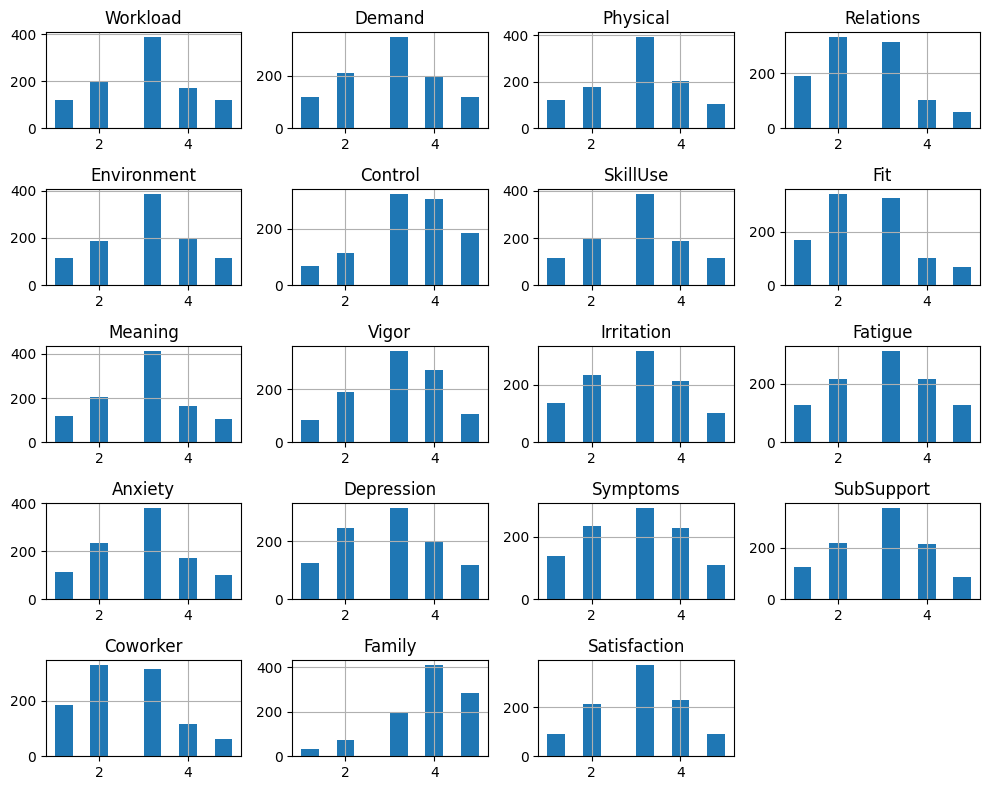

In [5]:
# ヒストグラム
df.hist(figsize=(10, 8))

plt.tight_layout()
plt.show()

In [6]:
# 歪度 (Skewness)
df.skew()

Workload        0.060502
Demand          0.029112
Physical       -0.056649
Relations       0.462205
Environment    -0.023673
Control        -0.394428
SkillUse        0.013721
Fit             0.473751
Meaning         0.074145
Vigor          -0.158136
Irritation      0.047683
Fatigue        -0.001923
Anxiety         0.115862
Depression      0.086708
Symptoms        0.025554
SubSupport     -0.000167
Coworker        0.426962
Family         -0.834118
Satisfaction   -0.029334
dtype: float64

In [7]:
# 尖度 (Kurtosis)
df.kurtosis()

Workload       -0.620072
Demand         -0.738693
Physical       -0.572837
Relations      -0.306564
Environment    -0.610813
Control        -0.442485
SkillUse       -0.599264
Fit            -0.264038
Meaning        -0.485134
Vigor          -0.604159
Irritation     -0.813611
Fatigue        -0.852983
Anxiety        -0.559443
Depression     -0.817315
Symptoms       -0.896705
SubSupport     -0.669760
Coworker       -0.389365
Family          0.278626
Satisfaction   -0.552534
dtype: float64

In [8]:
# 相関係数
df_corr = df.corr(method='spearman')

df_corr

,Workload,Demand,Physical,Relations,Environment,Control,SkillUse,Fit,Meaning,Vigor,Irritation,Fatigue,Anxiety,Depression,Symptoms,SubSupport,Coworker,Family,Satisfaction
Workload,1.000000,0.690770,0.035855,-0.031554,0.005902,-0.040503,0.010405,0.049297,-0.042837,0.079652,0.393734,0.339190,0.150698,0.158134,0.227721,-0.011620,-0.041032,0.035779,0.007765
Demand,0.690770,1.000000,0.331575,-0.008804,0.045504,-0.036171,0.023734,-0.025301,-0.004250,0.128043,0.548851,0.538471,0.292120,0.266068,0.325909,0.002273,-0.044308,0.060362,0.014634
Physical,0.035855,0.331575,1.000000,-0.002857,0.041787,0.035120,0.037638,-0.061728,0.049822,0.169042,0.281724,0.459819,0.246893,0.261617,0.279435,0.007884,-0.014090,0.056348,0.082865
Relations,-0.031554,-0.008804,-0.002857,1.000000,0.000941,-0.050324,-0.003475,-0.013093,-0.071388,-0.063036,0.146675,-0.007425,0.180711,0.087861,0.045092,0.035993,0.030898,0.022715,0.119948
Environment,0.005902,0.045504,0.041787,0.000941,1.000000,-0.005317,-0.026929,0.004917,-0.043329,0.056510,0.063372,0.197894,0.104400,0.078138,0.077423,0.021416,-0.013097,0.003775,-0.020598
Control,-0.040503,-0.036171,0.035120,-0.050324,-0.005317,1.000000,0.025875,-0.018155,0.007455,0.306524,-0.045988,-0.052843,-0.008056,-0.022599,-0.035745,-0.005269,0.048475,-0.044663,0.195725
SkillUse,0.010405,0.023734,0.037638,-0.003475,-0.026929,0.025875,1.000000,0.016072,0.032860,0.303339,0.044848,0.054937,0.005898,0.044678,0.062367,0.076857,-0.006398,0.026631,0.138381
Fit,0.049297,-0.025301,-0.061728,-0.013093,0.004917,-0.018155,0.016072,1.000000,-0.012149,-0.004731,-0.032508,0.022030,0.006247,0.009975,-0.007005,-0.026857,0.011702,0.008723,0.214014
Meaning,-0.042837,-0.004250,0.049822,-0.071388,-0.043329,0.007455,0.032860,-0.012149,1.000000,0.243573,-0.028316,-0.032570,0.002650,-0.057158,-0.037644,-0.038545,-0.015614,-0.034765,0.243264
Vigor,0.079652,0.128043,0.169042,-0.063036,0.056510,0.306524,0.303339,-0.004731,0.243573,1.000000,0.142382,0.274943,0.149690,0.184265,0.142930,0.129665,0.077257,-0.001674,0.412474


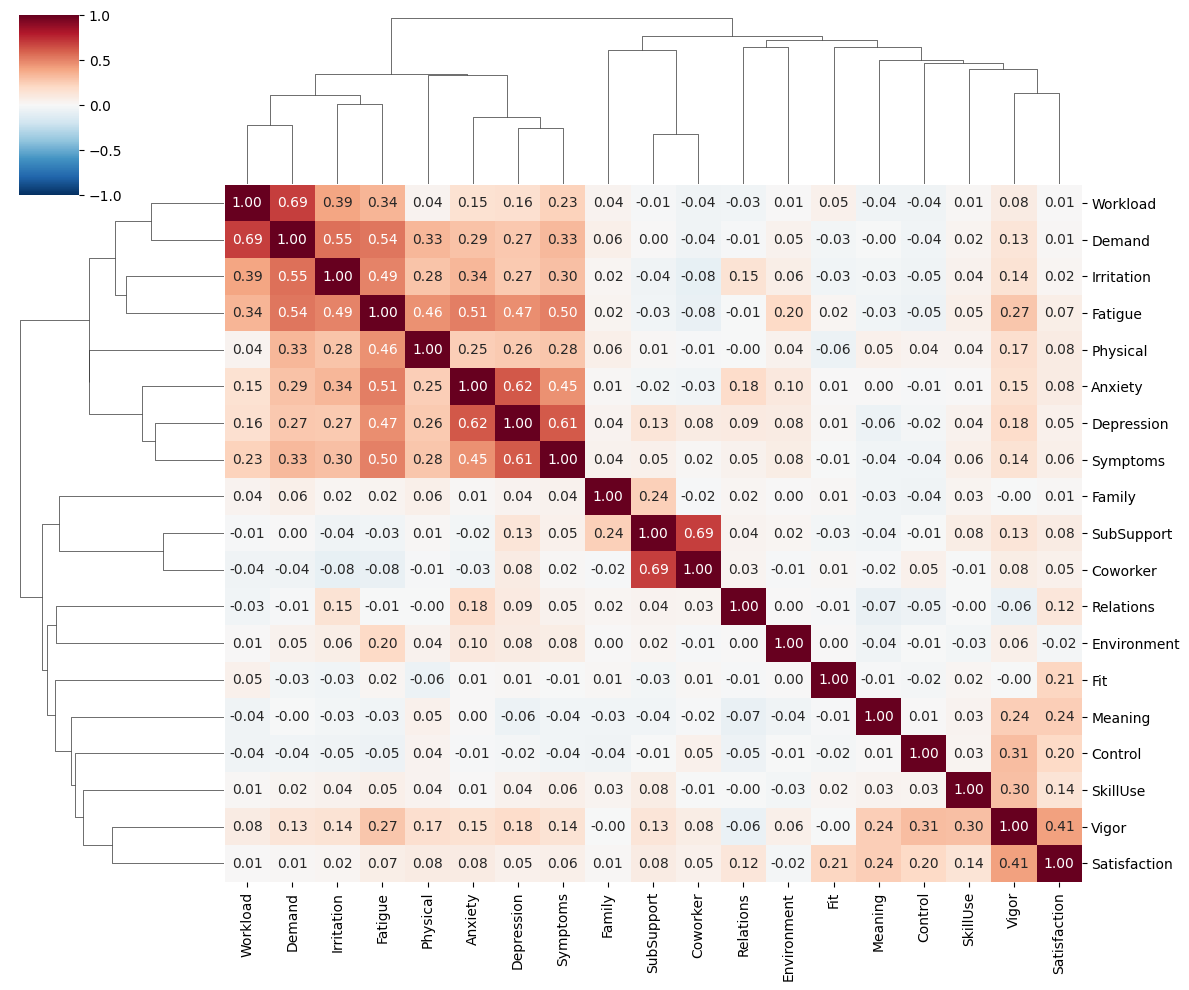

In [9]:
# クラスターマップ

sns.clustermap(
    corr,
    cmap='RdBu_r',
    center=0,
    annot=True,    
    fmt=".2f",
    figsize=(12,10),
    vmin=-1,
    vmax=1
)

In [10]:
# 正規性検定 Shapiro-Wilk検定

for col in df.columns: 
    stat, p = shapiro(df[col])

    print(
        f"{col:<15}: "
        f"stat={stat:<10.4f}"
        f"p={p:<10.4f}"
        f"正規性棄却={p < 0.05}"
    )

Workload       : stat=0.9104    p=0.0000    正規性棄却=True
Demand         : stat=0.9151    p=0.0000    正規性棄却=True
Physical       : stat=0.9111    p=0.0000    正規性棄却=True
Relations      : stat=0.8958    p=0.0000    正規性棄却=True
Environment    : stat=0.9120    p=0.0000    正規性棄却=True
Control        : stat=0.9006    p=0.0000    正規性棄却=True
SkillUse       : stat=0.9123    p=0.0000    正規性棄却=True
Fit            : stat=0.8955    p=0.0000    正規性棄却=True
Meaning        : stat=0.9078    p=0.0000    正規性棄却=True
Vigor          : stat=0.9147    p=0.0000    正規性棄却=True
Irritation     : stat=0.9163    p=0.0000    正規性棄却=True
Fatigue        : stat=0.9158    p=0.0000    正規性棄却=True
Anxiety        : stat=0.9126    p=0.0000    正規性棄却=True
Depression     : stat=0.9159    p=0.0000    正規性棄却=True
Symptoms       : stat=0.9155    p=0.0000    正規性棄却=True
SubSupport     : stat=0.9159    p=0.0000    正規性棄却=True
Coworker       : stat=0.8992    p=0.0000    正規性棄却=True
Family         : stat=0.8542    p=0.0000    正規性棄却=True
Satisfacti


因果順序の出力
[10, 11, 1, 0, 13, 14, 12, 2, 6, 18, 9, 4, 17, 16, 7, 3, 15, 8, 5]
['Irritation', 'Fatigue', 'Demand', 'Workload', 'Depression', 'Symptoms', 'Anxiety', 'Physical', 'SkillUse', 'Satisfaction', 'Vigor', 'Environment', 'Family', 'Coworker', 'Fit', 'Relations', 'SubSupport', 'Meaning', 'Control']

Adjacency Matrix
【列要素→行要素】の推定係数
              Workload    Demand  Physical  Relations  Environment  Control  \
Workload      0.000000  0.690429       0.0        0.0          0.0      0.0   
Demand        0.000000  0.000000       0.0        0.0          0.0      0.0   
Physical     -0.354747  0.374572       0.0        0.0          0.0      0.0   
Relations     0.000000 -0.091996       0.0        0.0          0.0      0.0   
Environment   0.000000  0.000000       0.0        0.0          0.0      0.0   
Control       0.000000  0.000000       0.0        0.0          0.0      0.0   
SkillUse      0.000000  0.000000       0.0        0.0          0.0      0.0   
Fit           0.000000  0.000000

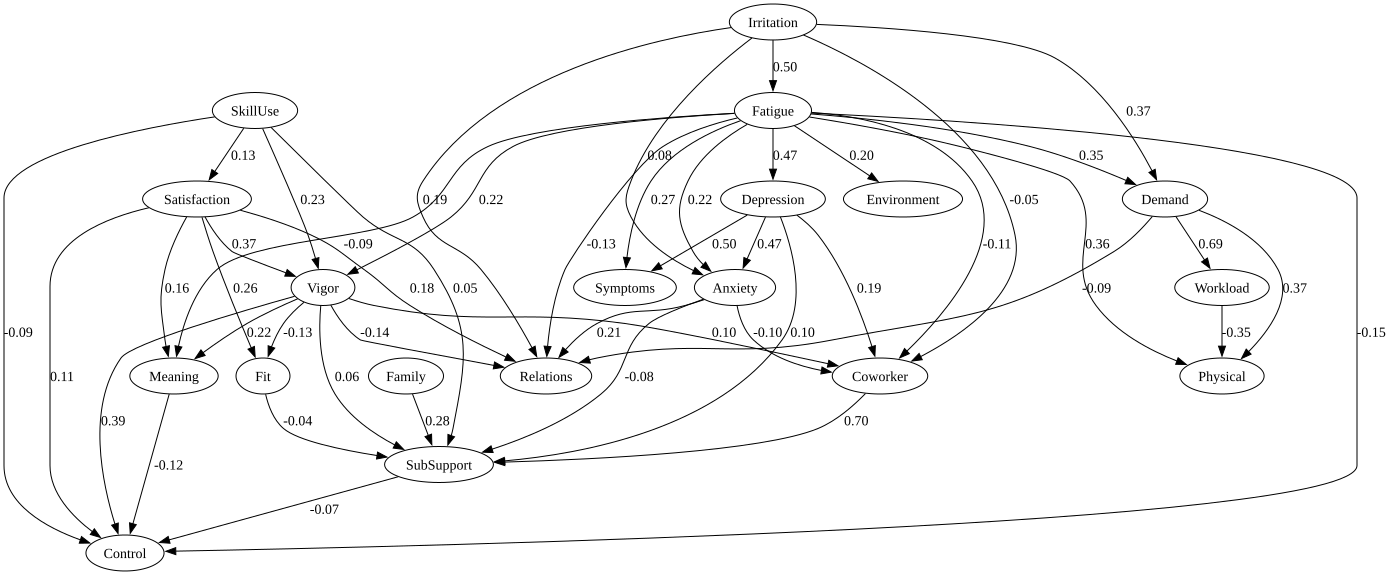

'causal_graph_stress_check_dummy.png'

In [11]:
# 因果探索の実行
#============================================================================================================
#1. DirectLiNGAM実行
#============================================================================================================
model = DirectLiNGAM()
model.fit(df)

#============================================================================================================
#2. 因果順序の取得
#============================================================================================================
print("\n因果順序の出力")
print(model.causal_order_)

names = [df.columns[i] for i in model.causal_order_]
print(names)

#============================================================================================================
#3. 因果係数(隣接行列)
#============================================================================================================
adj = pd.DataFrame(
    model.adjacency_matrix_,
    index=df.columns,
    columns=df.columns
)
print("\nAdjacency Matrix")
print("【列要素→行要素】の推定係数")
print(adj)

#============================================================================================================
#4. 因果グラフ描画
#============================================================================================================
dot = make_dot(
    model.adjacency_matrix_,
    labels=list(df.columns)
)

print("\n因果グラフ")
display(dot)

# 画像ファイルへ出力
dot.render(f"causal_graph_stress_check_dummy", format="png") 

In [12]:
#============================================================================================================
#5. bootstrap(サンプル変動に対する安定性)
#============================================================================================================
result = model.bootstrap(df.values, n_sampling=1000) 

#============================================================================================================
#6. 総因果効果
#============================================================================================================
effects = result.get_total_causal_effects()

#============================================================================================================
#7. 出力結果のソート
#============================================================================================================
# (fr, to, eff, prob)のタプルに変換し、昇順にソートする
sorted_effects = sorted(
    zip( 
        effects['from'],
        effects['to'],
        effects['effect'],
        effects['probability']
    ),
    key=lambda x: (abs(x[3]), x[2]), 
    reverse=True
)

# 出力形式 【fr -> to eff prob】
for fr, to, eff, prob in sorted_effects:
    print( 
        f"{df.columns[fr]:<20} "
        f" -> " 
        f"{df.columns[to]:<20} "
        f"【effect】 = {eff:6.3f} "
        f"【prob】 = {prob:5.3f}"
    )

Vigor                 -> Meaning              【effect】 =  0.253 【prob】 = 0.934
Satisfaction          -> Meaning              【effect】 =  0.217 【prob】 = 0.918
Vigor                 -> Control              【effect】 =  0.348 【prob】 = 0.917
Fatigue               -> Control              【effect】 = -0.068 【prob】 = 0.854
Fatigue               -> Meaning              【effect】 = -0.037 【prob】 = 0.838
Depression            -> Meaning              【effect】 = -0.045 【prob】 = 0.826
Depression            -> Control              【effect】 = -0.009 【prob】 = 0.806
Satisfaction          -> Control              【effect】 =  0.143 【prob】 = 0.794
Demand                -> Workload             【effect】 =  0.711 【prob】 = 0.790
Fatigue               -> Physical             【effect】 =  0.398 【prob】 = 0.759
Satisfaction          -> Fit                  【effect】 =  0.229 【prob】 = 0.733
SubSupport            -> Family               【effect】 =  0.447 【prob】 = 0.720
Fatigue               -> Environment          【effec

In [13]:
#============================================================================================================
#8. 誤差独立性検定
#============================================================================================================
p_values = model.get_error_independence_p_values(df) 

print(p_values)

[[0.00000000e+00 6.81112479e-03 9.56985678e-01 2.86803691e-01
  4.76690094e-01 7.80567671e-01 1.04594837e-01 3.22687897e-01
  5.51377948e-02 7.77752725e-01 3.60773549e-04 7.94476889e-01
  4.36747992e-01 6.15678907e-01 5.74061912e-01 3.46010174e-01
  7.72059636e-01 3.65279356e-01 3.64423524e-01]
 [6.81112479e-03 0.00000000e+00 2.37969936e-01 8.22813776e-02
  3.96314010e-01 5.10518722e-01 5.34218926e-01 7.83761132e-01
  7.16955051e-01 2.12157998e-01 1.04212480e-02 3.85394283e-01
  1.98969340e-02 8.83621913e-02 1.74586363e-01 3.95418328e-01
  7.61261195e-01 8.90891280e-01 2.23356283e-01]
 [9.56985678e-01 2.37969936e-01 0.00000000e+00 7.13503447e-01
  8.10238543e-01 2.44598602e-03 6.54039170e-01 8.04642304e-01
  1.79944069e-02 5.22102834e-02 9.08136061e-02 6.43310207e-01
  1.01000616e-02 1.59400080e-01 1.98301498e-01 4.69762369e-01
  4.84059999e-01 2.79931571e-02 3.47717777e-01]
 [2.86803691e-01 8.22813776e-02 7.13503447e-01 0.00000000e+00
  2.24077962e-01 1.08822762e-01 5.68736933e-01 4.1

In [14]:
# 誤差独立性が棄却されなかった組数
# 総数 361(=19×19)

n_independent = (p_values > 0.05).sum()
n_total = p_values.size

print(
    f"誤差独立性が棄却されなかった組数: "
    f"{n_independent}/{n_total} "
    f"({n_independent / n_total * 100:.1f}%)"
)

誤差独立性が棄却されなかった組数: 282/361 (78.1%)


In [15]:
# 誤差独立性検定
# 各組のp_valueをDataFrameとして作成

df_p_values = pd.DataFrame(
    p_values,
    index=df.columns,
    columns=df.columns
)

df_p_values

,Workload,Demand,Physical,Relations,Environment,Control,SkillUse,Fit,Meaning,Vigor,Irritation,Fatigue,Anxiety,Depression,Symptoms,SubSupport,Coworker,Family,Satisfaction
Workload,0.000000,0.006811,0.956986,0.286804,0.476690,0.780568,0.104595,0.322688,0.055138,0.777753,0.000361,0.794477,0.436748,0.615679,0.574062,3.460102e-01,7.720596e-01,0.365279,0.364424
Demand,0.006811,0.000000,0.237970,0.082281,0.396314,0.510519,0.534219,0.783761,0.716955,0.212158,0.010421,0.385394,0.019897,0.088362,0.174586,3.954183e-01,7.612612e-01,0.890891,0.223356
Physical,0.956986,0.237970,0.000000,0.713503,0.810239,0.002446,0.654039,0.804642,0.017994,0.052210,0.090814,0.643310,0.010100,0.159400,0.198301,4.697624e-01,4.840600e-01,0.027993,0.347718
Relations,0.286804,0.082281,0.713503,0.000000,0.224078,0.108823,0.568737,0.415173,0.016548,0.037763,0.695046,0.984825,0.598715,0.250975,0.405998,7.021866e-01,2.761720e-01,0.574450,0.753905
Environment,0.476690,0.396314,0.810239,0.224078,0.000000,0.397692,0.415205,0.593599,0.004140,0.463240,0.762421,0.102963,0.123419,0.059429,0.196982,3.873242e-02,9.393878e-01,0.809787,0.879520
Control,0.780568,0.510519,0.002446,0.108823,0.397692,0.000000,0.494701,0.252172,0.058354,0.000011,0.296871,0.838982,0.373638,0.020918,0.167541,2.755590e-01,6.906515e-01,0.508081,0.005978
SkillUse,0.104595,0.534219,0.654039,0.568737,0.415205,0.494701,0.000000,0.856750,0.142998,0.004906,0.989541,0.750752,0.644875,0.397818,0.531563,5.322824e-01,6.813673e-01,0.301216,0.691500
Fit,0.322688,0.783761,0.804642,0.415173,0.593599,0.252172,0.856750,0.000000,0.506398,0.491989,0.698456,0.645663,0.622839,0.633497,0.657419,8.743807e-01,2.633961e-01,0.663116,0.043524
Meaning,0.055138,0.716955,0.017994,0.016548,0.004140,0.058354,0.142998,0.506398,0.000000,0.001299,0.410517,0.731767,0.043236,0.298227,0.122515,6.322271e-01,8.409114e-01,0.767188,0.000056
Vigor,0.777753,0.212158,0.052210,0.037763,0.463240,0.000011,0.004906,0.491989,0.001299,0.000000,0.689165,0.909712,0.019686,0.294524,0.043564,8.588101e-01,1.019728e-01,0.061005,0.181019


In [16]:
#============================================================================================================
#9. 結果の出力
#============================================================================================================
sorted_effects_pvalue = sorted(
    sorted_effects,
    key=lambda x: (
        df_p_values.loc[
            df.columns[x[0]],
            df.columns[x[1]]
        ] <= 0.05
    )
)

for fr, to, eff, prob in sorted_effects_pvalue:

    src = df.columns[fr]
    dst = df.columns[to]

    p_val = df_p_values.loc[src, dst]
    corr  = df_corr.loc[src, dst]

    print(
        f"{src:<20} -> {dst:<20} "
        f"【effect】={eff:6.3f} "
        f"【ρ】={corr:6.3f} "
        f"【prob】={prob:5.3f} "
        f"【p_value】={p_val:7.5f} "
        f"【p>0.05】={p_val > 0.05}"
    )

Fatigue              -> Control              【effect】=-0.068 【ρ】=-0.053 【prob】=0.854 【p_value】=0.83898 【p>0.05】=True
Fatigue              -> Meaning              【effect】=-0.037 【ρ】=-0.033 【prob】=0.838 【p_value】=0.73177 【p>0.05】=True
Depression           -> Meaning              【effect】=-0.045 【ρ】=-0.057 【prob】=0.826 【p_value】=0.29823 【p>0.05】=True
Fatigue              -> Physical             【effect】= 0.398 【ρ】= 0.460 【prob】=0.759 【p_value】=0.64331 【p>0.05】=True
Fatigue              -> Environment          【effect】= 0.211 【ρ】= 0.198 【prob】=0.719 【p_value】=0.10296 【p>0.05】=True
SkillUse             -> Control              【effect】= 0.007 【ρ】= 0.026 【prob】=0.700 【p_value】=0.49470 【p>0.05】=True
SubSupport           -> Control              【effect】=-0.064 【ρ】=-0.005 【prob】=0.687 【p_value】=0.27556 【p>0.05】=True
Demand               -> Physical             【effect】= 0.231 【ρ】= 0.332 【prob】=0.684 【p_value】=0.23797 【p>0.05】=True
Symptoms             -> Control              【effect】=-0.024 【ρ】

In [17]:
# 誤差独立性が棄却されなかった組数
# 総数 342(=19×18)

count_p_gt_005 = sum(
    df_p_values.loc[df.columns[fr], df.columns[to]] > 0.05
    for fr, to, _, _ in sorted_effects
)

total_count = len(sorted_effects)

print(
    f"誤差独立性が棄却されなかった組数: "
    f"{count_p_gt_005}/{total_count} "
    f"({count_p_gt_005 / total_count * 100:.1f}%)"
)

誤差独立性が棄却されなかった組数: 282/342 (82.5%)
